Exploration for Q1

In [21]:
import sys
from pathlib import Path

# find the repo root (the folder that contains src/), wherever this notebook is saved
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "qkit.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

import config as cfg
import qkit


In [22]:
df = qkit.county_year(cfg.Q1_YEARS).merge(
    qkit.covariates(cfg.Q1_YEARS).drop(columns="county_name"),
    on=["fips", "year"], how="left", validate="1:1",
)

# Wilkin has no reporting food shelf: its activity is a true zero, not unknown
no_activity = df["households"].isna() & df["fi_persons"].notna()
for m in ["households", "pounds", "individuals"]:
    df.loc[no_activity, m] = 0
    df.loc[no_activity, f"{m}_per_fi"] = 0
df.loc[no_activity, "months_observed"] = 0

print(df.shape)
df.dtypes


(261, 35)


fips                               str
county_name                        str
year                             int64
households                     float64
pounds                         float64
individuals                    float64
months_observed                float64
source_edition                     str
fi_rate                        float64
fi_persons                     float64
child_fi_rate                  float64
fi_children                    float64
cost_per_meal                  float64
annual_shortfall               float64
rucc_2013                      float64
rucc_2023                      float64
snap_threshold                 float64
pct_fi_below_snap_threshold    float64
pct_fi_above_snap_threshold    float64
households_per_fi              float64
pounds_per_fi                  float64
individuals_per_fi             float64
population                       int64
households_census                int64
poverty_rate                   float64
child_poverty_rate       

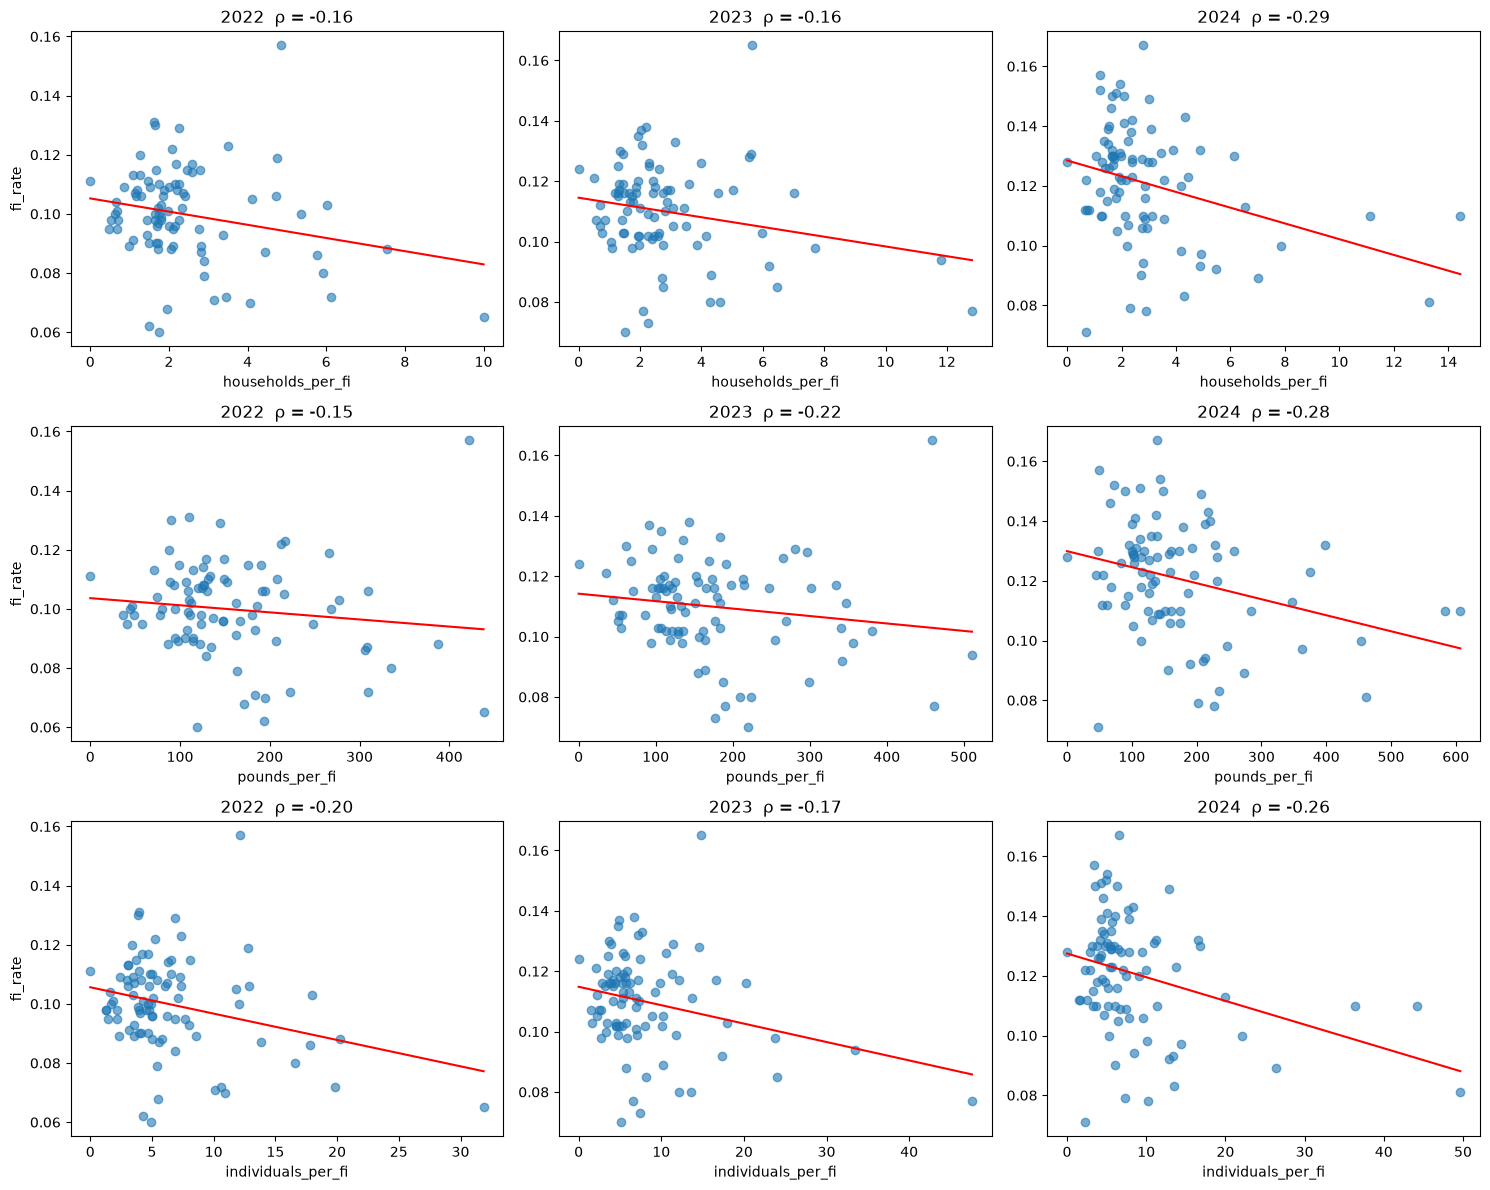

metric,households_per_fi,individuals_per_fi,pounds_per_fi
year,,,
2022,-0.164,-0.195,-0.145
2023,-0.163,-0.173,-0.219
2024,-0.293,-0.262,-0.285


In [23]:
metrics = ["households_per_fi", "pounds_per_fi", "individuals_per_fi"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(metrics), len(years), figsize=(5 * len(years), 4 * len(metrics)))

rows = []
for i, met in enumerate(metrics):
    for j, yr in enumerate(years):
        g = df[df["year"] == yr].dropna(subset=[met, "fi_rate"])
        ax = axes[i, j]
        ax.scatter(g[met], g["fi_rate"], alpha=0.6)
        m, b = np.polyfit(g[met], g["fi_rate"], 1)
        xs = np.linspace(g[met].min(), g[met].max(), 100)
        ax.plot(xs, m * xs + b, color="red")
        rho = g[met].corr(g["fi_rate"], method="spearman")
        ax.set_title(f"{yr}  ρ = {rho:.2f}")
        ax.set_xlabel(met)
        if j == 0:
            ax.set_ylabel("fi_rate")
        rows.append({"year": yr, "metric": met, "spearman": rho, "n": len(g)})

plt.tight_layout()
plt.show()
pd.DataFrame(rows).pivot(index="year", columns="metric", values="spearman").round(3)


### Two caveats on those correlations
1. **The negative sign is partly built in.** The x-axis divides by `fi_persons` and the
   y-axis (`fi_rate`) multiplies by it, so the two would correlate negatively even with
   random data. Activity per 1,000 *residents* does not share that term; the table below
   shows it next to the per-FI-person version. The defensible statement is *activity does
   not rise with need intensity* — not *higher need means less activity per person*.
   The residual ranking further down does not have this problem.
2. **2024 uses a different MMG edition** (2026) from 2022–23 (2025). Feeding America
   re-estimates the model each edition, so the stronger 2024 numbers may be a modelling
   change rather than a real shift. Do not describe it as a trend.

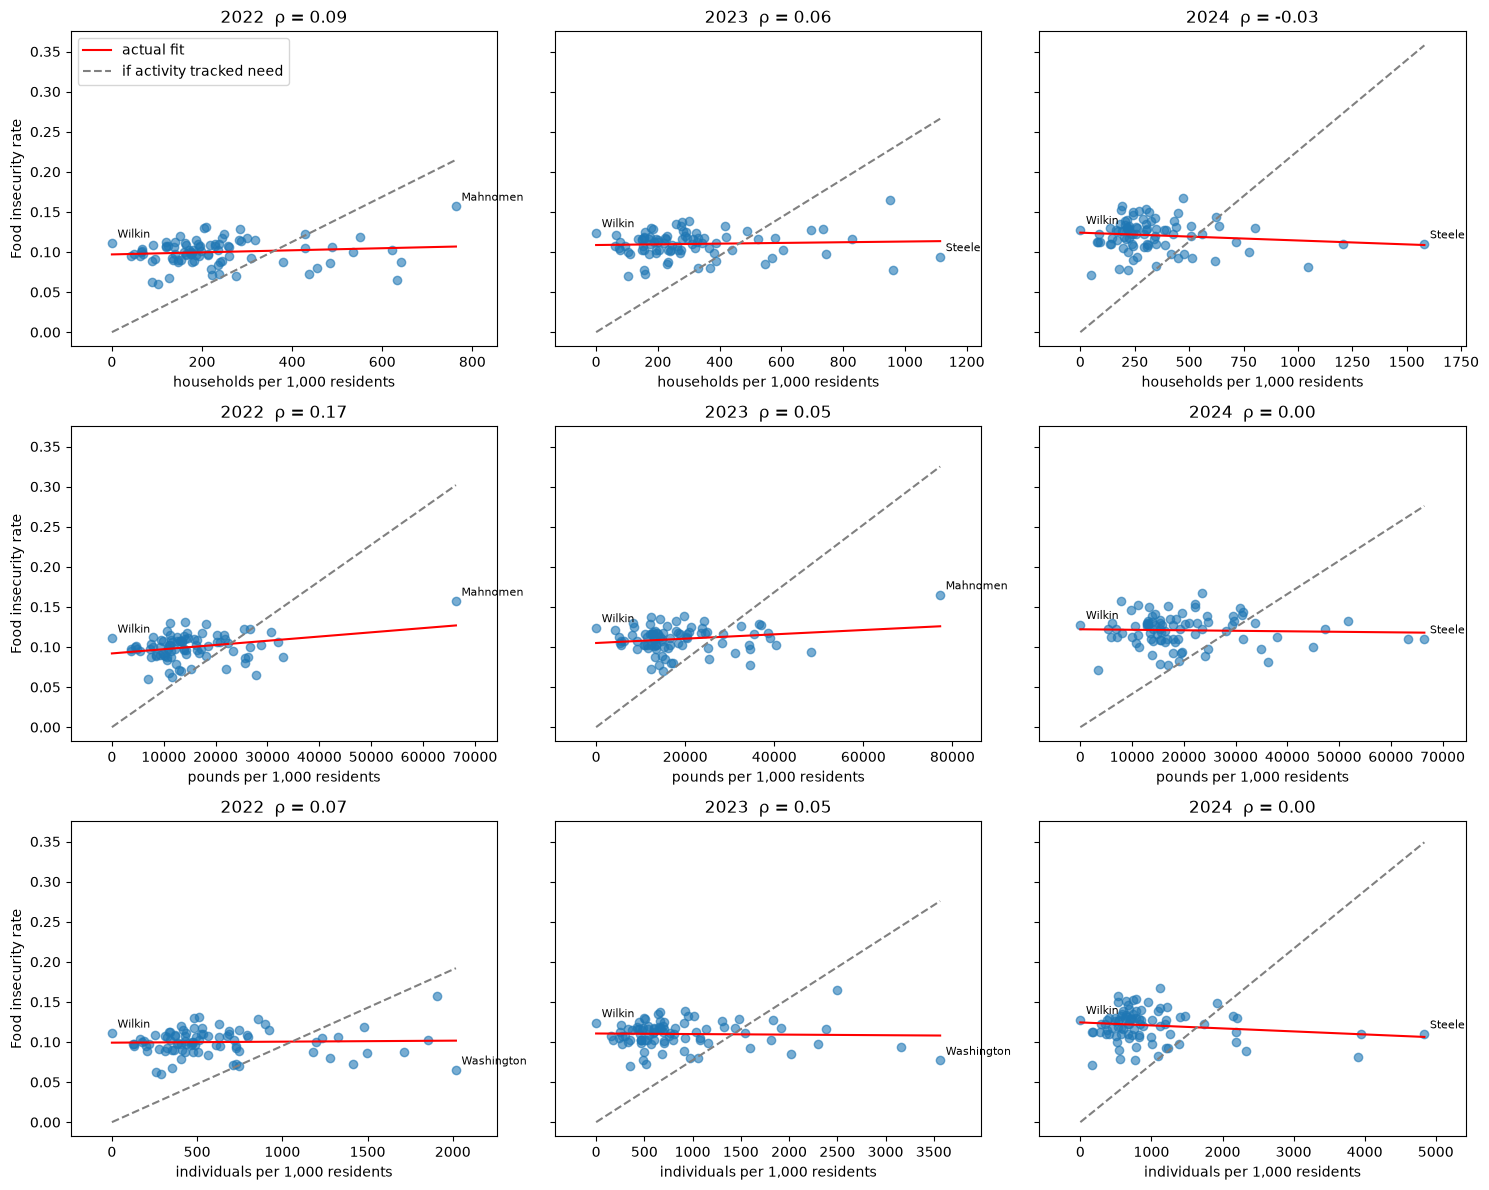

In [24]:
count_metrics = ["households", "pounds", "individuals"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(count_metrics), len(years),
                         figsize=(5 * len(years), 4 * len(count_metrics)), sharey=True)

for i, met in enumerate(count_metrics):
    for j, yr in enumerate(years):
        g = df[df["year"] == yr]
        ax = axes[i, j]

        x = 1e3 * g[met] / g["population"]           # activity per 1,000 residents
        y = g["fi_rate"]
        k = g[met].sum() / g["fi_persons"].sum()      # statewide activity per food-insecure person

        ax.scatter(x, y, alpha=0.6)
        ax.margins(x=0.12)   # room for the county labels at the right edge
        m, b = np.polyfit(x, y, 1)
        xs = np.linspace(0, x.max(), 100)
        ax.plot(xs, m * xs + b, color="red", label="actual fit")
        ax.plot(xs, xs / (1e3 * k), color="grey", linestyle="--", label="if activity tracked need")

        # name the two counties a reader will ask about: the far-right dot and Wilkin at zero
        for name in [g.loc[x.idxmax(), "county_name"], "Wilkin"]:
            r = g[g["county_name"] == name].iloc[0]
            ax.annotate(name, (1e3 * r[met] / r["population"], r["fi_rate"]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)

        rho = x.corr(y, method="spearman")
        ax.set_title(f"{yr}  ρ = {rho:.2f}")
        ax.set_xlabel(f"{met} per 1,000 residents")
        if j == 0:
            ax.set_ylabel("Food insecurity rate")

axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()


In [25]:
rows = []
for met in ["households", "pounds", "individuals"]:
    for yr in years:
        g = df[df["year"] == yr]
        rows.append({"year": yr, "metric": met,
                     "per food-insecure person": g[f"{met}_per_fi"].corr(g["fi_rate"], method="spearman"),
                     "per 1,000 residents": (1e3 * g[met] / g["population"]).corr(g["fi_rate"], method="spearman")})
pd.DataFrame(rows).set_index(["year", "metric"]).round(3)

,,per food-insecure person,"per 1,000 residents"
year,metric,,
2022,households,-0.164,0.093
2023,households,-0.163,0.057
2024,households,-0.293,-0.029
2022,pounds,-0.145,0.167
2023,pounds,-0.219,0.050
2024,pounds,-0.285,0.003
2022,individuals,-0.195,0.073
2023,individuals,-0.173,0.047
2024,individuals,-0.262,0.001


## The fit itself: log activity on log food-insecure persons
One fit per metric and year, nine in all, before anything is averaged. Both axes are on a
log scale, so the slope reads as a percentage: a slope of 1.2 means that a county with 1%
more food-insecure people has about 1.2% more activity.

- **Grey dashed line, slope 1:** what proportional service would look like. Twice the
  need, twice the activity.
- **Red line:** what the data shows.
- **Distance of a dot from the red line:** that county's residual, used in the ranking
  below.

This view forms no ratio, so it has neither the built-in negative tilt of the
per-food-insecure-person chart nor the leftover county size of the per-1,000-residents
chart. R² will be high here because both axes grow with county size; the slope and the
residuals carry the finding, not R². Intervals use robust (HC3) standard errors. Wilkin
is left out because the log of zero is undefined.

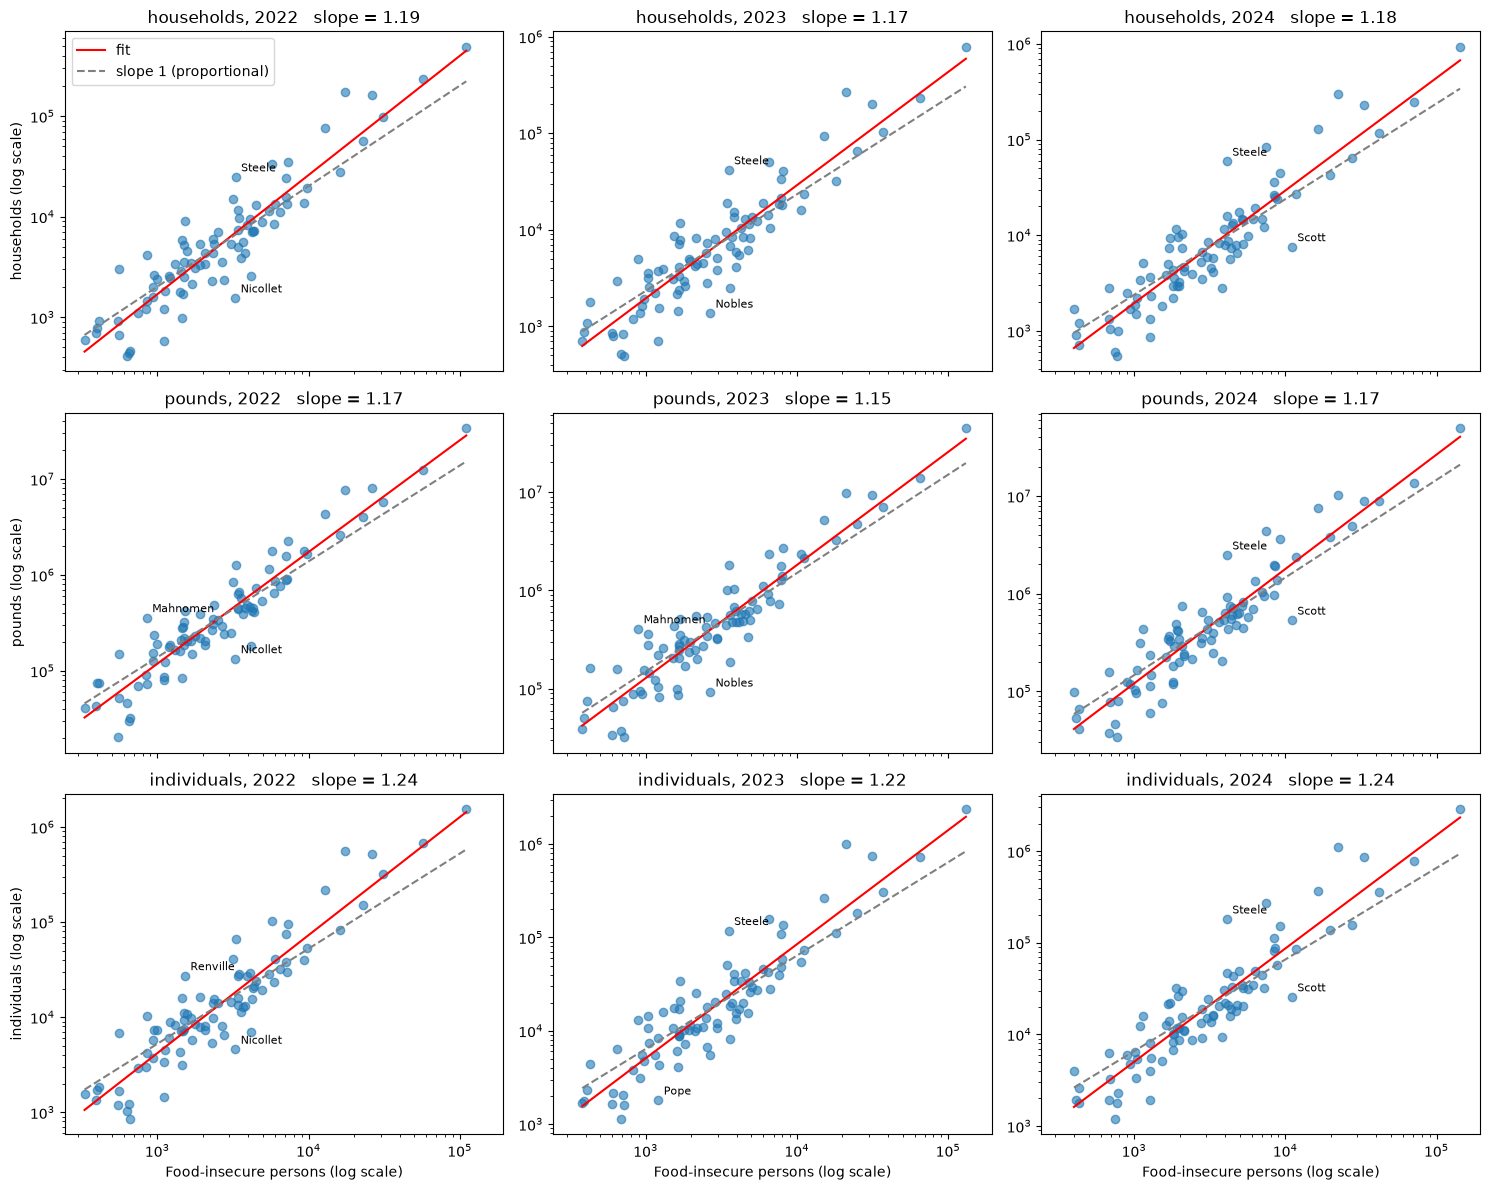

slope  ci_low  ci_high     r2   n
metric      year                                   
households  2022  1.186   1.087    1.286  0.850  86
            2023  1.172   1.067    1.278  0.836  86
            2024  1.178   1.067    1.289  0.845  86
pounds      2022  1.165   1.078    1.253  0.884  86
            2023  1.149   1.057    1.241  0.866  86
            2024  1.172   1.080    1.264  0.870  86
individuals 2022  1.241   1.137    1.345  0.855  86
            2023  1.222   1.112    1.332  0.845  86
            2024  1.237   1.120    1.354  0.848  86

In [26]:
count_metrics = ["households", "pounds", "individuals"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(count_metrics), len(years),
                         figsize=(5 * len(years), 4 * len(count_metrics)), sharex=True)

fit_rows = []
for i, met in enumerate(count_metrics):
    for j, yr in enumerate(years):
        g = df[(df["year"] == yr) & (df[met] > 0)].copy()
        fit = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit(cov_type="HC3")
        intercept, slope = fit.params.iloc[0], fit.params.iloc[1]
        ci_low, ci_high = fit.conf_int().iloc[1]
        g["resid"] = fit.resid

        ax = axes[i, j]
        ax.scatter(g["fi_persons"], g[met], alpha=0.6)
        xs = np.geomspace(g["fi_persons"].min(), g["fi_persons"].max(), 50)
        ax.plot(xs, np.exp(intercept) * xs ** slope, color="red", label="fit")

        # slope 1 through the middle of the data: proportional service
        k = np.exp(np.log(g[met]).mean() - np.log(g["fi_persons"]).mean())
        ax.plot(xs, k * xs, color="grey", linestyle="--", label="slope 1 (proportional)")

        # name the county furthest below the line and the one furthest above
        for idx in (g["resid"].idxmin(), g["resid"].idxmax()):
            ax.annotate(g.loc[idx, "county_name"], (g.loc[idx, "fi_persons"], g.loc[idx, met]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(f"{met}, {yr}   slope = {slope:.2f}")
        if i == len(count_metrics) - 1:
            ax.set_xlabel("Food-insecure persons (log scale)")
        if j == 0:
            ax.set_ylabel(f"{met} (log scale)")

        fit_rows.append({"metric": met, "year": yr, "slope": slope, "ci_low": ci_low,
                         "ci_high": ci_high, "r2": fit.rsquared, "n": int(fit.nobs)})

axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

loglog = pd.DataFrame(fit_rows).set_index(["metric", "year"]).round(3)
loglog

### What the fit says
**Recorded food-shelf activity rises faster than need.** A county with ten times as many
food-insecure people records about sixteen times the activity (10^1.2 is about 16), so
activity per food-insecure person is higher in counties with more need.

- The slopes run from 1.15 to 1.24 across the nine fits, and every interval sits above 1.
- "Records" is deliberate: activity is counted where the food shelf is, not where the
  household lives.

### Sub-questions 1 and 2: answers
**1. Do the two tell the same story?** On raw counts they agree: counties with higher need
record more activity. Part of that is built in, because counties with more food-insecure
people have more people, and so record more of everything. On rates they disagree: a higher
food-insecurity rate is not related to a meaningful increase in activity per 1,000
residents. This holds for all three metrics in all three years.

**2. Which metric correlates most and least?** Pounds is highest, individuals next,
households lowest, in the same order in all three years. The gap is about 3 percentage
points of R2 (0.87 against 0.84), and individuals and households are less than 0.01 apart:
consistent but small.

In [27]:
metrics = ["households", "pounds", "individuals"]
res = []
for met in metrics:
    for yr in sorted(df["year"].unique()):
        g = df[(df["year"] == yr) & (df[met] > 0)].dropna(subset=["fi_persons"]).copy()
        fit = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit()
        g["resid"] = fit.resid
        res.append(g[["fips", "county_name", "year", "months_observed", "fi_rate", "resid"]]
                   .assign(metric=met))
res = pd.concat(res)

# counties below the line in every metric and year: need does not show up as demand
summary = (res.groupby(["county_name"])
              .agg(mean_resid=("resid", "mean"),
                   n_below=("resid", lambda r: (r < 0).sum()),
                   n=("resid", "size"),
                   min_months=("months_observed", "min"))
              .sort_values("mean_resid"))
print("Estimated need > observed demand")
display(summary.head(10).round(3))
print("Observed demand > estimated need")
display(summary.tail(10).round(3))


Estimated need > observed demand


,mean_resid,n_below,n,min_months
county_name,,,,
Nicollet,-1.208,9,9,12.0
Pope,-0.942,9,9,12.0
Lac qui Parle,-0.882,9,9,12.0
Benton,-0.877,9,9,12.0
Norman,-0.867,9,9,12.0
Roseau,-0.760,9,9,12.0
Scott,-0.673,7,9,12.0
Nobles,-0.635,8,9,12.0
Todd,-0.552,9,9,12.0


Observed demand > estimated need


,mean_resid,n_below,n,min_months
county_name,,,,
Dodge,0.680,0,9,12.0
Olmsted,0.733,0,9,12.0
Pipestone,0.757,0,9,12.0
Kittson,0.780,0,9,12.0
Mahnomen,0.865,0,9,12.0
Cook,0.890,0,9,12.0
Renville,1.034,0,9,12.0
Rice,1.069,0,9,12.0
Washington,1.211,0,9,12.0


### Robustness: food-shelf-like sites only
The frame above counts every site type. Some counties get a large share of their pounds
from sites that are not food shelves (Cook 57%, Faribault 50%, Anoka 47%). Re-run the
ranking with only food-shelf-like sites and see which counties move.

In [28]:
df_fs = qkit.county_year(cfg.Q1_YEARS, food_shelf_only=True)
res_fs = []
for met in ["households", "pounds", "individuals"]:
    for yr in years:
        g = df_fs[(df_fs["year"] == yr) & (df_fs[met] > 0)].copy()
        g["resid"] = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit().resid
        res_fs.append(g[["county_name", "resid"]])

cmp = pd.DataFrame({"all_sites": summary["mean_resid"],
                    "food_shelf_only": pd.concat(res_fs).groupby("county_name")["resid"].mean()})
cmp["shift"] = cmp["food_shelf_only"] - cmp["all_sites"]
print("Spearman between the two rankings:",
      round(cmp["all_sites"].corr(cmp["food_shelf_only"], method="spearman"), 3))
cmp.reindex(cmp["shift"].abs().sort_values(ascending=False).index).head(5).round(2)

Spearman between the two rankings: 0.936


,all_sites,food_shelf_only,shift
county_name,,,
Cook,0.89,-0.12,-1.01
Faribault,0.04,-0.82,-0.86
Anoka,0.59,0.11,-0.48
Carlton,-0.42,-0.88,-0.46
Mower,0.06,-0.32,-0.38


## Where estimated need and observed demand disagree
Mean residual across all 9 metric-years.

- **Red:** estimated need is higher than observed demand. Fewer people show up at food
  shelves than the county's food-insecure population predicts.
- **Blue:** observed demand is higher than estimated need. More people show up than the
  county's own population predicts.

Several red counties border blue ones (Nicollet / Blue Earth, Roseau / Kittson,
Benton / Sherburne), which is consistent with residents crossing county lines to the
nearest food shelf rather than going unserved. Counties marked * had fewer than 12 months
of reporting in some year, so part of their gap may be missing data.

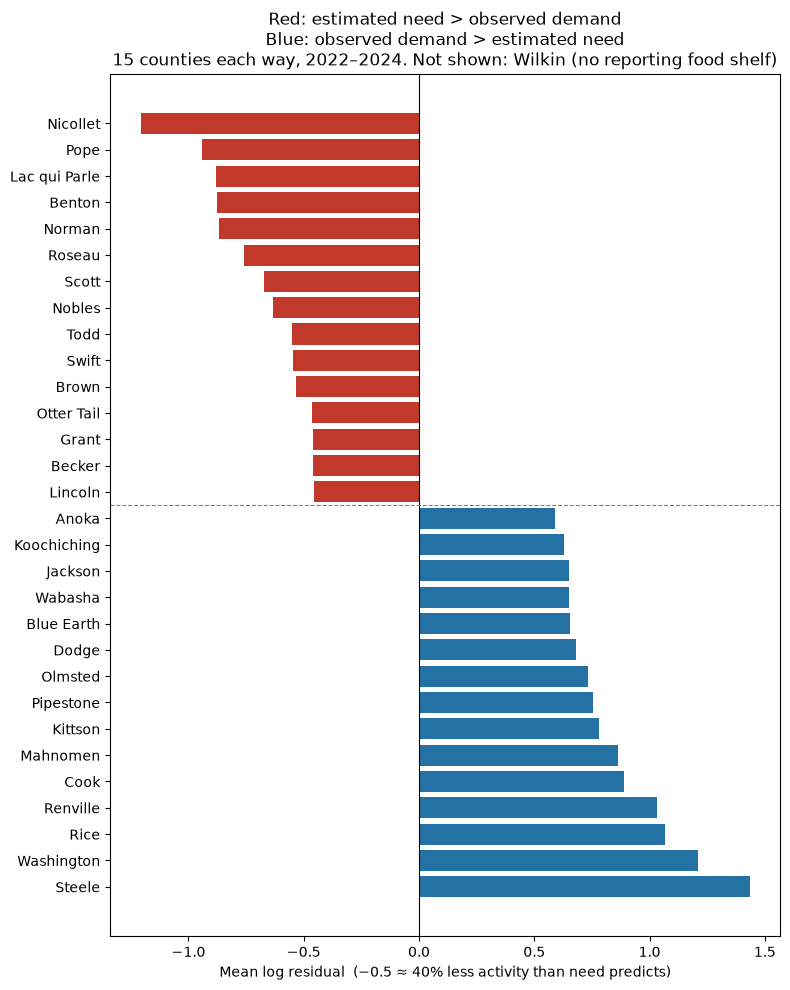

In [29]:
k = 15
show = pd.concat([summary.head(k), summary.tail(k)])
labels = [f"{c} *" if mm < 12 else c for c, mm in zip(show.index, show["min_months"])]
colors = ["#c0392b" if v < 0 else "#2471a3" for v in show["mean_resid"]]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(range(len(show)), show["mean_resid"], color=colors)
ax.set_yticks(range(len(show)), labels)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.axhline(k - 0.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Mean log residual  (−0.5 ≈ 40% less activity than need predicts)")
ax.set_title("Red: estimated need > observed demand\n"
             "Blue: observed demand > estimated need\n"
             f"{k} counties each way, 2022–2024. Not shown: Wilkin (no reporting food shelf)")
plt.tight_layout()
plt.show()

### Sub-question 3: answer
**Wilkin has no reporting food shelf and no recorded activity, so it is the most extreme
breakdown in the data.** It is left out of the fits because log of zero is undefined, not
because it does not matter. Of the counties with activity, Nicollet, Pope and Lac qui Parle
record the least compared with what need predicts; Steele, Washington and Rice record the
most.

- Size: Nicollet's mean residual of -1.2 is about 30% of predicted activity; Steele's +1.4
  is about 4 times predicted.
- All six are on the same side of the line in all 9 metric-years (`n_below` is 9 or 0).
- None of the six moves in the food-shelf-only check. Cook does: it is in the top ten with
  all site types and near zero with food shelves only.

### Do neighbouring counties look alike? (Moran's I)
The chart above suggests red counties sit next to blue ones. Moran's I puts one number on
that: it compares each county's residual with the average residual of the counties it
borders. Near +1, neighbours are alike; near 0, no spatial pattern; negative, neighbours
are opposite. The expected value with no pattern is -1/(n-1), about -0.01 here.

Neighbours come from the Census County Adjacency File 2023 (`data/external/census/adjacency`).
Counties are weighted equally within each county's neighbour list. Wilkin is left out, as
in the fits. The p-value comes from shuffling the residuals across counties 999 times.

**Prediction, written before running the cell:** the spillover story says a county that
records more than need predicts is taking visits from its neighbours, who then record
less, so Moran's I should be **negative**. Neighbours could instead look alike if they
share the same kind of place (similar distance to a metro county, similar rurality),
which would push I towards positive. Expected pattern: metro counties positive, the
counties bordering them negative, and fully rural counties negative but less so.

**Result:** the prediction did not hold. I = 0.06 against -0.01 expected with no pattern, p = 0.37. A county's residual is not related to the residuals of its neighbouring counties in general. There may be a relationship in particular pairs, but a global statistic does not test that, and the red/blue chart's border pairs are examples of what may be happening, not evidence that it is. The test also cannot separate no spillover from spillover cancelled by neighbours sharing the same kind of place.

Moran's I = 0.063 | expected with no pattern = -0.012 | permutation p = 0.374 | n = 86


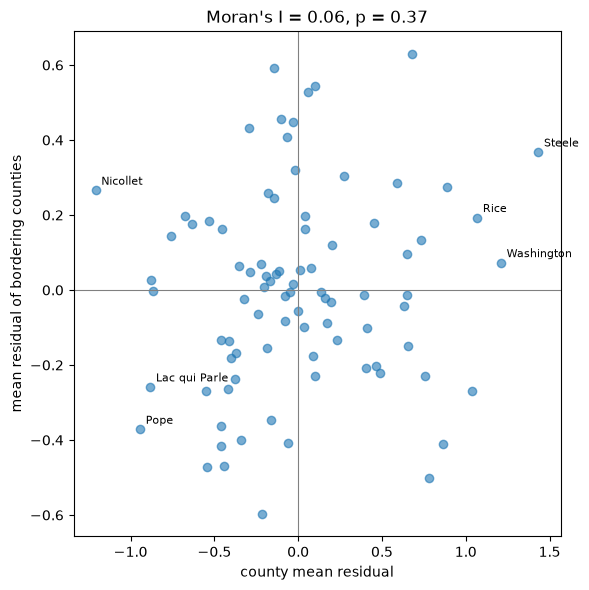

,mean,median,count
group,,,
borders metro,-0.003,-0.077,37
metro,0.048,-0.032,27
neither,-0.053,-0.064,22


In [30]:
# Moran's I on the mean residual, using the Census county adjacency file
adj = pd.read_csv(cfg.EXTERNAL / "census" / "adjacency" / "county_adjacency2023.txt",
                  sep="|", dtype=str)
adj.columns = ["county", "fips", "neighbor", "nfips"]
adj = adj[adj["fips"].str.startswith("27") & adj["nfips"].str.startswith("27")
          & (adj["fips"] != adj["nfips"])]

r = res.groupby("fips")["resid"].mean()
r.index = r.index.astype(str).str.zfill(5)
adj = adj[adj["fips"].isin(r.index) & adj["nfips"].isin(r.index)]   # drops Wilkin
counties = r.index
W = pd.DataFrame(0.0, index=counties, columns=counties)
for a, b in zip(adj["fips"], adj["nfips"]):
    W.loc[a, b] = 1.0
W = W.div(W.sum(axis=1), axis=0)                    # each row sums to 1

def morans_i(x, W):
    z = x - x.mean()
    return (len(z) / W.values.sum()) * (z @ W.values @ z) / (z @ z)

I_obs = morans_i(r.values, W)
rng = np.random.default_rng(0)
I_perm = np.array([morans_i(rng.permutation(r.values), W) for _ in range(999)])
p = (np.sum(np.abs(I_perm) >= abs(I_obs)) + 1) / (len(I_perm) + 1)
print(f"Moran's I = {I_obs:.3f} | expected with no pattern = {-1 / (len(r) - 1):.3f} "
      f"| permutation p = {p:.3f} | n = {len(r)}")

# Moran scatter: each county against the average of its neighbours
lag = pd.Series(W.values @ r.values, index=counties)
names = res.drop_duplicates("fips").set_index(res.drop_duplicates("fips")["fips"].astype(str).str.zfill(5))["county_name"]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(r, lag, alpha=0.6)
for f in pd.concat([r.nsmallest(3), r.nlargest(3)]).index:
    ax.annotate(names[f], (r[f], lag[f]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("county mean residual")
ax.set_ylabel("mean residual of bordering counties")
ax.set_title(f"Moran's I = {I_obs:.2f}, p = {p:.2f}")
plt.tight_layout()
plt.show()

# The predicted pattern: metro, borders a metro county, neither
rucc = df.drop_duplicates("fips").set_index(df.drop_duplicates("fips")["fips"].astype(str).str.zfill(5))["rucc_2023"]
metro = rucc[rucc <= 3].index
borders_metro = adj[adj["nfips"].isin(metro)]["fips"].unique()
grp = pd.Series("neither", index=counties)
grp[grp.index.isin(borders_metro)] = "borders metro"
grp[grp.index.isin(metro)] = "metro"
pd.DataFrame({"resid": r, "group": grp}).groupby("group")["resid"].agg(["mean", "median", "count"]).round(3)

## Sub-question 4: what explains the mismatch?

**Outcome:** the residual from the log-log fit above, averaged over the three metrics, one
row per county-year. Positive = more food-shelf activity than need predicts. Wilkin has no
residual (no activity) and is not in the model.

**Hypotheses, written before looking at any result.** Each one answers: *two counties with
the same number of food-insecure people; one has more X; does it have more or less
food-shelf activity?*

| variable | family | expected sign | mechanism | alternative |
|---|---|---|---|---|
| `mean_km_to_site` | rural | − | farther to travel | |
| `rucc` group (metro / non-metro town / rural) | rural | − for rural vs metro | harder to serve | grouping by metro adjacency was considered; town size chosen |
| `pct_no_vehicle` | deprivation | − | cannot reach the site or carry food home | |
| `pct_hh_snap` | deprivation | + | complement: households on SNAP are already connected to assistance | substitute (−): SNAP covers groceries, less need for a food shelf |
| `poverty_rate` | | side check only | input to the MMG model, so circular as an explanation | |

Left out on purpose: `sites_per_10k` (nearly restates the outcome), `log population` and
`pct_senior` (both move with `rucc`, Spearman about −0.8 and +0.7).

**Design:** county-years (3 per county), year dummies, standard errors clustered on
county because the three years of one county are not independent observations.

In [31]:
# One row per county-year: mean residual across the three metrics + the chosen covariates
q4 = (res.groupby(["fips", "county_name", "year"], as_index=False)["resid"].mean()
         .merge(df[["fips", "year", "mean_km_to_site", "rucc_2023", "pct_no_vehicle",
                    "pct_hh_snap", "poverty_rate"]], on=["fips", "year"], how="left"))

q4["rucc_group"] = pd.cut(q4["rucc_2023"], bins=[0, 3, 7, 9],
                          labels=["metro", "nonmetro_town", "rural"])

# z-scores: a coefficient then reads "effect of one standard deviation", comparable across variables
num = ["mean_km_to_site", "pct_no_vehicle", "pct_hh_snap", "poverty_rate"]
for v in num:
    q4[v + "_z"] = (q4[v] - q4[v].mean()) / q4[v].std()

q4["county_id"] = q4["fips"].astype("category").cat.codes   # integer id for clustering

# 0/1 dummies, written out by hand so every column in the model is visible.
# Baselines: metro counties, year 2022.
q4["nonmetro_town"] = (q4["rucc_group"] == "nonmetro_town").astype(int)
q4["rural"] = (q4["rucc_group"] == "rural").astype(int)
q4["y2023"] = (q4["year"] == 2023).astype(int)
q4["y2024"] = (q4["year"] == 2024).astype(int)

print(q4.shape, "|", q4["fips"].nunique(), "counties |", q4[num].isna().sum().sum(), "missing covariate values")
q4.groupby("rucc_group", observed=True)["fips"].nunique()

(258, 19) | 86 counties | 0 missing covariate values


rucc_group
metro            27
nonmetro_town    25
rural            34
Name: fips, dtype: int64

### Look before modelling
Spearman of each candidate against the residual, then how the candidates relate to each
other. Compare the signs with the hypothesis table above.

,spearman_with_resid
mean_km_to_site,-0.229
pct_no_vehicle,-0.080
pct_hh_snap,-0.111
poverty_rate,-0.122
rucc_2023,-0.040


,mean_km_to_site,pct_no_vehicle,pct_hh_snap,poverty_rate,rucc_2023
mean_km_to_site,1.00,-0.12,0.14,0.25,0.53
pct_no_vehicle,-0.12,1.00,0.55,0.55,-0.05
pct_hh_snap,0.14,0.55,1.00,0.72,0.24
poverty_rate,0.25,0.55,0.72,1.00,0.40
rucc_2023,0.53,-0.05,0.24,0.40,1.00


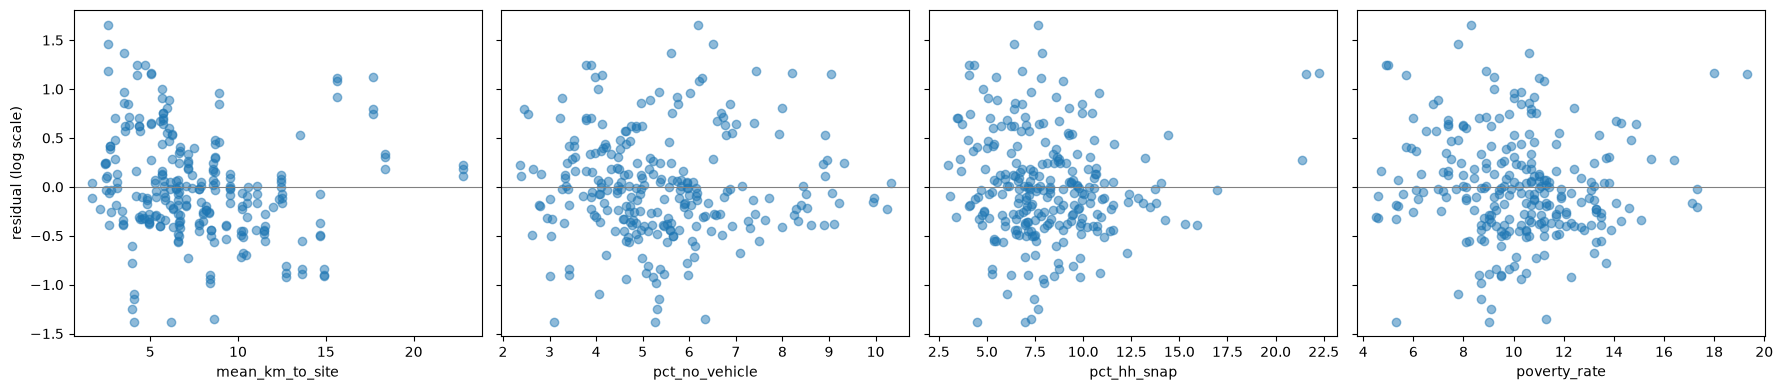

,mean,median,count
rucc_group,,,
metro,0.048,-0.031,81
nonmetro_town,-0.067,-0.164,75
rural,0.011,-0.006,102


In [32]:
look = pd.DataFrame({
    "spearman_with_resid": [q4[v].corr(q4["resid"], method="spearman") for v in num + ["rucc_2023"]],
}, index=num + ["rucc_2023"]).round(3)
display(look)
display(q4[num + ["rucc_2023"]].corr(method="spearman").round(2))

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, v in zip(axes, num):
    ax.scatter(q4[v], q4["resid"], alpha=0.5)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel(v)
axes[0].set_ylabel("residual (log scale)")
plt.tight_layout()
plt.show()

q4.groupby("rucc_group", observed=True)["resid"].agg(["mean", "median", "count"]).round(3)

### The model (fit once)
Read each coefficient as: the change in the residual for a one standard deviation increase
in that variable, holding the others fixed. `nonmetro_town` and `rural` are compared
against metro counties; `y2023` and `y2024` against 2022. Residuals are on a log scale, so a coefficient of −0.10 is roughly 10% less
activity than need predicts.

In [33]:
def coef_table(fit):
    """Coefficients with clustered standard errors, p-values and 95% intervals."""
    ci = fit.conf_int()
    return pd.DataFrame({"coef": fit.params, "se": fit.bse, "p": fit.pvalues,
                         "ci_low": ci[0], "ci_high": ci[1]}).round(3)

def fit_clustered(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="cluster",
                                          cov_kwds={"groups": data["county_id"]})

COVARIATES = ("mean_km_to_site_z + nonmetro_town + rural "
              "+ pct_no_vehicle_z + pct_hh_snap_z + y2023 + y2024")

m_main = fit_clustered("resid ~ " + COVARIATES, q4)
print("n =", int(m_main.nobs), "| counties =", q4["county_id"].nunique(), "| R2 =", round(m_main.rsquared, 3))
coef_table(m_main)

n = 258 | counties = 86 | R2 = 0.033


,coef,se,p,ci_low,ci_high
Intercept,-0.026,0.119,0.825,-0.260,0.207
mean_km_to_site_z,-0.103,0.074,0.163,-0.247,0.042
nonmetro_town,-0.056,0.151,0.712,-0.353,0.241
rural,0.096,0.152,0.527,-0.201,0.393
pct_no_vehicle_z,-0.008,0.056,0.881,-0.118,0.101
pct_hh_snap_z,-0.016,0.078,0.836,-0.169,0.136
y2023,0.000,0.027,0.999,-0.052,0.052
y2024,0.014,0.045,0.758,-0.074,0.102


### Side check: add poverty
Poverty is an input to the MMG need estimate, so this is not part of the explanation. It
answers a different question: do the other coefficients change when poverty is held fixed?

In [34]:
m_pov = fit_clustered("resid ~ " + COVARIATES + " + poverty_rate_z", q4)
print("R2 =", round(m_pov.rsquared, 3))
pd.concat({"main": coef_table(m_main)[["coef", "p"]],
           "with poverty": coef_table(m_pov)[["coef", "p"]]}, axis=1)

R2 = 0.034


main        with poverty       
                    coef      p         coef      p
Intercept         -0.026  0.825       -0.034  0.784
mean_km_to_site_z -0.103  0.163       -0.099  0.184
nonmetro_town     -0.056  0.712       -0.046  0.773
rural              0.096  0.527        0.109  0.508
pct_no_vehicle_z  -0.008  0.881        0.000  0.996
pct_hh_snap_z     -0.016  0.836       -0.002  0.982
y2023              0.000  0.999        0.001  0.978
y2024              0.014  0.758        0.012  0.780
poverty_rate_z       NaN    NaN       -0.028  0.725

### Appendix: one model per metric
Same model, fitted to each metric's own residual instead of the average. If the three
columns agree in sign, the averaged model is a fair summary.

In [35]:
cov = q4.drop(columns=["resid"])
per_metric = {}
for met in ["households", "pounds", "individuals"]:
    d = res[res["metric"] == met][["fips", "year", "resid"]].merge(cov, on=["fips", "year"])
    per_metric[met] = coef_table(fit_clustered("resid ~ " + COVARIATES, d))[["coef", "p"]]
pd.concat(per_metric, axis=1)

households        pounds        individuals       
                        coef      p   coef      p        coef      p
Intercept              0.004  0.973 -0.068  0.522      -0.015  0.911
mean_km_to_site_z     -0.083  0.295 -0.110  0.105      -0.116  0.141
nonmetro_town         -0.079  0.638 -0.006  0.966      -0.083  0.626
rural                  0.040  0.805  0.160  0.238       0.087  0.611
pct_no_vehicle_z      -0.015  0.801 -0.002  0.969      -0.008  0.900
pct_hh_snap_z         -0.005  0.950 -0.031  0.696      -0.012  0.876
y2023                 -0.001  0.972  0.002  0.950      -0.001  0.981
y2024                  0.009  0.836  0.018  0.712       0.014  0.760

### Robustness: one step instead of two
The model above works in two steps (fit activity on need, then explain what is left). If a
covariate is itself related to the number of food-insecure people, two steps can understate
its effect. This fits everything at once for households; the covariate coefficients should
look similar to the two-step households column.

In [36]:
one = df[df["households"] > 0].merge(
    q4[["fips", "year", "nonmetro_town", "rural", "y2023", "y2024", "county_id"]
       + [v + "_z" for v in num]], on=["fips", "year"])
m_one = fit_clustered("np.log(households) ~ np.log(fi_persons) + " + COVARIATES, one)
pd.concat({"two-step (households)": per_metric["households"],
           "one-step (households)": coef_table(m_one)[["coef", "p"]]}, axis=1)

two-step (households)        one-step (households)       
                                    coef      p                  coef      p
Intercept                          0.004  0.973                -0.357  0.569
mean_km_to_site_z                 -0.083  0.295                -0.088  0.273
nonmetro_town                     -0.079  0.638                -0.107  0.534
rural                              0.040  0.805                -0.022  0.907
pct_no_vehicle_z                  -0.015  0.801                -0.003  0.964
pct_hh_snap_z                     -0.005  0.950                -0.009  0.910
y2023                             -0.001  0.972                 0.130  0.000
y2024                              0.009  0.836                 0.150  0.001
np.log(fi_persons)                   NaN    NaN                 1.139  0.000

### Robustness: the other RUCC grouping (metro adjacency)
The main model splits non-metro counties by town size (RUCC 4-7 against 8-9). The
alternative in the hypothesis table splits them by whether the county borders a metro area:
RUCC 4, 6, 8 are adjacent, RUCC 5, 7, 9 are not. Metro counties (1-3) stay the baseline, and
every other variable is unchanged.

**Prediction, written before running the cell:**

| variable | expected sign against metro | why |
|---|---|---|
| `nonmetro_adjacent` | *-* | Being next to a metro area increases it's availability to food shelves, driving down demand for that counties food shelf as they can cross the border |
| `nonmetro_remote` | *+* | There is no nearby food shleve available form a metro area, so the need has to be fulfilled more locally, increasing demand for food shelves, and thus how much is provided in that county.  |

What to look at: whether the two new coefficients differ from each other, whether the other
coefficients move, and whether R2 changes.

In [37]:
# Same model, non-metro counties split by metro adjacency instead of town size
q4["nonmetro_adjacent"] = q4["rucc_2023"].isin([4, 6, 8]).astype(int)
q4["nonmetro_remote"] = q4["rucc_2023"].isin([5, 7, 9]).astype(int)

groups = q4.drop_duplicates("fips")
print("counties | metro:", int((groups["rucc_2023"] <= 3).sum()),
      "| adjacent:", int(groups["nonmetro_adjacent"].sum()),
      "| remote:", int(groups["nonmetro_remote"].sum()))

m_adj = fit_clustered("resid ~ mean_km_to_site_z + nonmetro_adjacent + nonmetro_remote "
                      "+ pct_no_vehicle_z + pct_hh_snap_z + y2023 + y2024", q4)
print("R2 | town size:", round(m_main.rsquared, 3), "| adjacency:", round(m_adj.rsquared, 3))

cols = ["coef", "p", "ci_low", "ci_high"]
pd.concat({"town size (main)": coef_table(m_main)[cols],
           "metro adjacency": coef_table(m_adj)[cols]}, axis=1)

counties | metro: 27 | adjacent: 32 | remote: 27
R2 | town size: 0.033 | adjacency: 0.038


town size (main)                       metro adjacency  \
                              coef      p ci_low ci_high            coef   
Intercept                   -0.026  0.825 -0.260   0.207          -0.016   
mean_km_to_site_z           -0.103  0.163 -0.247   0.042          -0.099   
nonmetro_town               -0.056  0.712 -0.353   0.241             NaN   
rural                        0.096  0.527 -0.201   0.393             NaN   
pct_no_vehicle_z            -0.008  0.881 -0.118   0.101          -0.023   
pct_hh_snap_z               -0.016  0.836 -0.169   0.136          -0.002   
y2023                        0.000  0.999 -0.052   0.052          -0.002   
y2024                        0.014  0.758 -0.074   0.102           0.010   
nonmetro_adjacent              NaN    NaN    NaN     NaN          -0.057   
nonmetro_remote                NaN    NaN    NaN     NaN           0.111   

                                         
                       p ci_low ci_high  
Intercept          0.893 -0.256   0.223  
mean_km_to_site_z  0.184 -0.246   0.047  
nonmetro_town        NaN    NaN     NaN  
rural                NaN    NaN     NaN  
pct_no_vehicle_z   0.687 -0.134   0.088  
pct_hh_snap_z      0.979 -0.167   0.163  
y2023              0.949 -0.055   0.051  
y2024              0.824 -0.080   0.101  
nonmetro_adjacent  0.675 -0.326   0.211  
nonmetro_remote    0.527 -0.233   0.456

### Appendix: one variable at a time, and two more covariates
Two checks the advisor asked for. First, each covariate on its own (with year dummies and
the same clustering), to show the joint model is not hiding anything. Second, covariates
that test whether the mismatch is partly about what got counted rather than need against
demand:

- `log_sites`: log of the number of reporting sites in the county-year. Logged because the
  count is skewed (Hennepin against a one-site county). This is supply side, so a
  relationship would not explain need; it would say the residual partly measures capacity.
- `months_missing` (12 minus the months with data) was planned, with a predicted negative
  sign: missing months would be periods where need was met but cannot be seen. The check
  below shows every county-year with activity has all 12 months in 2022-2024, so there is
  nothing to test, and the * marking in the red/blue chart never applies in these years.
  Data coverage is not the explanation.

**Predictions, written before running the cell:**

| variable | expected sign | why |
|---|---|---|
| `log_sites` | + | more sites, more activity can be recorded |

Five single-variable fits means five tests, so the bar for "significant" is 0.05 / 5 = 0.01,
not 0.05.

**Result:** one at a time, the coefficient for rural flips sign, but every interval is as wide as before and the conclusion is the same as in the joint model. The site count has the predicted sign and is the strongest single variable (R2 0.032 alone, as much as the other four together), but at p = 0.06 it is not clearly associated with the residual, and as with distance the design lacks the power to test an effect of this size. Adding it also weakens distance (-0.10 to -0.07), because counties with many sites are counties with short distances. Part of this is built in: the only measure of demand is where activity was recorded, and counties with more sites record more activity per food-insecure person, whether because recording follows capacity or because sites open where people show up.

In [38]:
# One covariate at a time, then the main model with the site count added
extra = q4.merge(df[["fips", "year", "n_sites_reporting", "months_observed"]],
                 on=["fips", "year"], how="left")
assert extra["n_sites_reporting"].min() >= 1
extra["log_sites"] = np.log(extra["n_sites_reporting"])
print("county-years with fewer than 12 months of data:", int((extra["months_observed"] < 12).sum()),
      "| sites per county-year: min", int(extra["n_sites_reporting"].min()),
      "median", int(extra["n_sites_reporting"].median()),
      "max", int(extra["n_sites_reporting"].max()))

alone = []
for v in ["mean_km_to_site_z", "nonmetro_town + rural", "pct_no_vehicle_z", "pct_hh_snap_z",
          "log_sites"]:
    fit = fit_clustered(f"resid ~ {v} + y2023 + y2024", extra)
    alone.append(coef_table(fit).drop(["Intercept", "y2023", "y2024"]).assign(r2=round(fit.rsquared, 3)))
print("Bonferroni bar for five tests: p <", round(0.05 / 5, 3))
display(pd.concat(alone))

m_ext = fit_clustered("resid ~ " + COVARIATES + " + log_sites", extra)
print("R2 | main:", round(m_main.rsquared, 3), "| with sites:", round(m_ext.rsquared, 3))
coef_table(m_ext)

county-years with fewer than 12 months of data: 0 | sites per county-year: min 1 median 3 max 92
Bonferroni bar for five tests: p < 0.01


,coef,se,p,ci_low,ci_high,r2
mean_km_to_site_z,-0.076,0.069,0.269,-0.211,0.059,0.020
nonmetro_town,-0.115,0.141,0.416,-0.391,0.162,0.007
rural,-0.037,0.137,0.786,-0.307,0.232,0.007
pct_no_vehicle_z,-0.003,0.048,0.949,-0.097,0.091,0.000
pct_hh_snap_z,-0.016,0.068,0.817,-0.148,0.117,0.001
log_sites,0.110,0.058,0.058,-0.004,0.223,0.032


R2 | main: 0.033 | with sites: 0.055


,coef,se,p,ci_low,ci_high
Intercept,-0.213,0.196,0.279,-0.598,0.172
mean_km_to_site_z,-0.072,0.080,0.368,-0.228,0.084
nonmetro_town,0.028,0.174,0.874,-0.313,0.368
rural,0.179,0.168,0.286,-0.150,0.508
pct_no_vehicle_z,-0.033,0.058,0.570,-0.147,0.081
pct_hh_snap_z,-0.009,0.080,0.911,-0.166,0.148
y2023,-0.002,0.026,0.944,-0.053,0.050
y2024,0.018,0.046,0.693,-0.072,0.108
log_sites,0.119,0.085,0.161,-0.047,0.285


### Robustness: the covariate model on food-shelf-only residuals
The ranking barely moved when non-food-shelf sites were dropped (Spearman 0.94 between the
two rankings). This checks that the covariate model does not move either. Residuals are
refitted on the food-shelf-only frame; the covariates are the same rows as `q4`. County-years
with no food-shelf activity drop out, so n can be below 258.

Expected: the same picture. Distance about -0.1, everything else near zero, R2 a few percent.

In [39]:
# Same model, residuals from the food-shelf-only frame
rf = []
for met in ["households", "pounds", "individuals"]:
    for yr in years:
        g = df_fs[(df_fs["year"] == yr) & (df_fs[met] > 0)].copy()
        g["resid"] = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit().resid
        rf.append(g[["fips", "year", "resid"]])
q4_fs = (pd.concat(rf).groupby(["fips", "year"], as_index=False)["resid"].mean()
           .merge(q4.drop(columns="resid"), on=["fips", "year"], how="inner"))

m_fs = fit_clustered("resid ~ " + COVARIATES, q4_fs)
print("n =", int(m_fs.nobs), "| R2 all sites:", round(m_main.rsquared, 3),
      "| food shelves only:", round(m_fs.rsquared, 3))
pd.concat({"all sites": coef_table(m_main)[["coef", "p"]],
           "food shelves only": coef_table(m_fs)[["coef", "p"]]}, axis=1)

n = 258 | R2 all sites: 0.033 | food shelves only: 0.048


all sites        food shelves only       
                       coef      p              coef      p
Intercept            -0.026  0.825            -0.051  0.677
mean_km_to_site_z    -0.103  0.163            -0.130  0.071
nonmetro_town        -0.056  0.712            -0.019  0.898
rural                 0.096  0.527             0.126  0.418
pct_no_vehicle_z     -0.008  0.881             0.017  0.758
pct_hh_snap_z        -0.016  0.836            -0.029  0.714
y2023                 0.000  0.999             0.001  0.958
y2024                 0.014  0.758             0.019  0.710

### Sub-question 4: answer
**The county characteristics we tested explain 3% of the mismatch, and none shows a clear
association.** Distance to the nearest site is the one to follow up: about 10% less recorded
activity per extra 4 km, but there is not enough data for a firm conclusion.

- The interval for distance runs from about -25% to +4% per 4 km (one standard deviation),
  so it includes zero.
- No clear association is not the same as no association. With 86 counties the model can
  only detect large effects.
- Rural counties and non-metro counties that do not border a metro area both have positive
  coefficients of about 0.10, with intervals too wide to say anything in either direction.
- The signs agree across households, pounds and individuals, and the conclusion is the same
  under both RUCC groupings. The three metrics come from the same sites, so this is one
  finding seen three ways.

## Exploration: clustering (not for slides)
Two k-means runs, done to see what they give. Neither answers a Q1 sub-question.

1. **Cluster on the residuals.** One row per county, nine columns (metric x year). If the
   nine columns mostly say the same thing, the clusters will just be low / middle / high,
   which the ranking already gives. The first line of output checks that: the share of
   variance carried by the first principal component.
2. **Cluster on the covariates**, then compare the residual across clusters. County types
   rather than single variables. Kruskal-Wallis tests whether the clusters differ in
   residual; with about 20 counties per cluster only a large difference would show.

Expected: nothing beyond what the ranking and the regression already say.

In [40]:
from scipy.cluster.vq import kmeans2
from scipy.stats import kruskal

def kmeans(X, k, seed=0):
    """k-means with 20 restarts; returns labels and total within-cluster sum of squares."""
    best = None
    for s in range(20):
        cent, lab = kmeans2(np.asarray(X, float), k, minit="++", seed=seed + s)
        sse = sum(((X[lab == j] - cent[j]) ** 2).sum() for j in range(k))
        if best is None or sse < best[1]:
            best = (lab, sse)
    return best

# 1) residual clusters: county x (metric, year)
R = res.pivot_table(index="county_name", columns=["metric", "year"], values="resid")
sv = np.linalg.svd(R.values - R.values.mean(axis=0), compute_uv=False)
print("share of residual variance on the first component:", round(sv[0] ** 2 / (sv ** 2).sum(), 2))

R["cluster"], _ = kmeans(R.values, 3)
order = R.groupby("cluster")[R.columns[:-1]].mean().mean(axis=1).sort_values().index
lab = {c: name for c, name in zip(order, ["low", "middle", "high"])}
R["cluster"] = R["cluster"].map(lab)
print(R.groupby("cluster").size().rename("counties"))
for name in ["low", "high"]:
    print(name + ":", ", ".join(sorted(R.index[R["cluster"] == name])))

share of residual variance on the first component: 0.86
cluster
high      21
low       23
middle    42
Name: counties, dtype: int64
low: Becker, Benton, Brown, Carlton, Chippewa, Douglas, Grant, Kandiyohi, Lac qui Parle, Lincoln, Lyon, Morrison, Nicollet, Nobles, Norman, Otter Tail, Pope, Roseau, Scott, Stearns, Swift, Todd, Wadena
high: Anoka, Blue Earth, Cass, Cook, Dodge, Houston, Jackson, Kittson, Koochiching, Mahnomen, Mille Lacs, Olmsted, Pipestone, Red Lake, Renville, Rice, Sherburne, Steele, Wabasha, Washington, Watonwan


inertia by k (look for the bend): {2: 406, 3: 327, 4: 280, 5: 236, 6: 210, 7: 187, 8: 172}

cluster profiles (means of the raw variables; population is log):


,mean_km_to_site,pct_no_vehicle,pct_hh_snap,poverty_rate,pct_senior,rucc_2023,population,n
cluster,,,,,,,,
0,5.22,6.51,8.45,10.65,17.86,3.69,10.86,26
1,5.45,3.84,5.11,6.43,16.23,1.64,11.26,14
2,8.02,7.43,15.61,14.93,19.38,8.20,9.21,5
3,9.82,4.96,7.97,10.54,22.87,7.98,9.49,41


mean residual by cluster:


,mean,median,count
cluster,,,
0,-0.044,-0.145,26
1,0.234,0.170,14
2,0.070,-0.116,5
3,-0.060,-0.066,41


Kruskal-Wallis p = 0.213


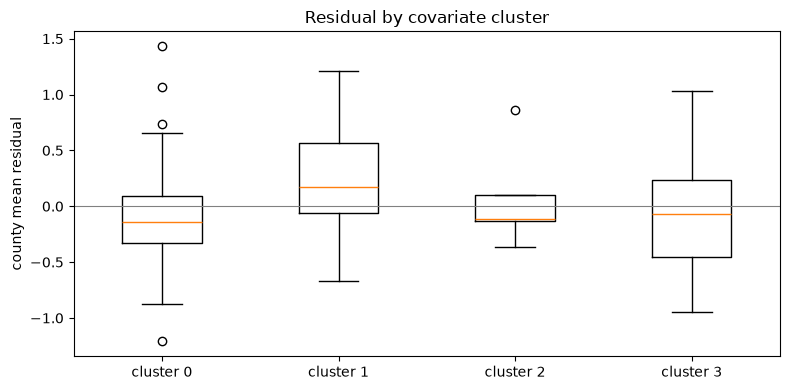

In [41]:
# 2) covariate clusters: one row per county (mean over the three years)
feat = ["mean_km_to_site", "pct_no_vehicle", "pct_hh_snap", "poverty_rate", "pct_senior",
        "rucc_2023", "population"]
prof = df[df["households"] > 0].groupby("county_name")[feat].mean()
prof["population"] = np.log(prof["population"])
Z = (prof - prof.mean()) / prof.std()

inertia = {k: kmeans(Z.values, k)[1] for k in range(2, 9)}
print("inertia by k (look for the bend):", {k: round(v) for k, v in inertia.items()})

K = 4
prof["cluster"], _ = kmeans(Z.values, K)
prof["resid"] = summary["mean_resid"]
print("\ncluster profiles (means of the raw variables; population is log):")
display(prof.groupby("cluster")[feat].mean().round(2).assign(n=prof.groupby("cluster").size()))
print("mean residual by cluster:")
display(prof.groupby("cluster")["resid"].agg(["mean", "median", "count"]).round(3))
groups = [g["resid"].dropna().values for _, g in prof.groupby("cluster")]
print("Kruskal-Wallis p =", round(kruskal(*groups).pvalue, 3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(groups, positions=range(K))
ax.set_xticks(range(K))
ax.set_xticklabels([f"cluster {i}" for i in range(K)])
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("county mean residual")
ax.set_title("Residual by covariate cluster")
plt.tight_layout()
plt.show()